# BANKING77: classifying many queries per call (batch prompting)

So far, every call classified one query. The prompt, however, is dominated by the list of 77 intents; the query
itself is a few tokens. **Batch prompting** puts several numbered queries into one call and asks for one label per
query. The label list is sent once per batch instead of once per query, which is attractive with APIs that bill
per token.

The open question: does the model still classify each query as well when it sees many at once, and does that
depend on the model size?

Setup: `qwen3.5:2b`, `4b`, `9b` and the mixture-of-experts `qwen3.6:35b-a3b` (3B active parameters, partly on the
CPU, so its times are not comparable with the others), thinking off, same balanced subset as before (5 queries per intent, 385 queries).
The queries are shuffled and split into batches of 1, 5, 10, 20 and 40, with two different random orders (seeds).
The answer is constrained to a JSON object with one key per query number, each restricted to the 77 labels, so the
model always returns exactly one valid label per query. Run with `scripts/run_batching.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import stratified_subset
from slm.evaluation.batch_classification import BatchClassifier, evaluate_batches
from slm.inference import OllamaBackend

MODELS = ["qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b", "qwen3.6:35b-a3b"]
BATCH_SIZES = [1, 5, 10, 20, 40]
SEEDS = [0, 1]
RUN_DIR = RESULTS_DIR / "banking77" / "batching"
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#8a4fc7"]))
GRAY = "#a3a29d"

dataset = load_banking77()
subset = stratified_subset(dataset.test, per_class=5)

results = {}
for model in MODELS:
    classifier = BatchClassifier(OllamaBackend(model, num_ctx=8192), dataset.labels)
    for bs in BATCH_SIZES:
        for seed in SEEDS:
            cache = RUN_DIR / model.replace(":", "_") / f"bs{bs}_seed{seed}.jsonl"
            r = results[model, bs, seed] = evaluate_batches(classifier, subset, bs, seed, cache)
            r["correct"] = r["prediction"] == r["label"]

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. What the model sees

In [2]:
print(classifier.system_prompt[-400:], "\n")
batch = subset.sample(5, random_state=0)["text"].tolist()
print("\n".join(f"{i}. {text}" for i, text in enumerate(batch, 1)), "\n")
print(json.dumps(classifier.schema(2), indent=1)[:300], "...")

- cash_withdrawal_not_recognised
- exchange_charge
- top_up_by_card_charge
- activate_my_card
- cash_withdrawal_charge
- card_about_to_expire
- apple_pay_or_google_pay
- verify_my_identity
- country_support

You will receive several numbered messages. Classify each message on its own and answer with a JSON object that maps each message number to its intent, e.g. {"1": "<intent>", "2": "<intent>"}. 

1. Why has my card payment been cancelled?
2. Tell me why my virtual disposable card won't work.
3. What do I need to do to change the address on my account?
4. Is it possible to change to another currency?
5. I would like a refund for something I bought 

{
 "type": "object",
 "properties": {
  "1": {
   "type": "string",
   "enum": [
    "card_arrival",
    "card_linking",
    "exchange_rate",
    "card_payment_wrong_exchange_rate",
    "extra_charge_on_statement",
    "pending_cash_withdrawal",
    "fiat_currency_support",
    "card_delivery_estima ...


## 2. Accuracy and cost vs. batch size

Time per query is the time of a call divided by the number of queries in it (4 concurrent calls, as before).
`35b-a3b` runs partly on the CPU, where reading the long prompt is slow, so it gains most from batching.
Values are the mean over the two random batch orders. All four models share the same tokenizer, so the prompt
tokens per query are the same for all of them.

In [3]:
summary = pd.DataFrame([{"model": model, "batch_size": bs, "seed": seed, "accuracy": r["correct"].mean(),
                         "time_per_query_s": r["latency_s"].mean(), "prompt_tokens_per_query": r["prompt_tokens"].mean()}
                        for (model, bs, seed), r in results.items()])
mean = summary.groupby(["model", "batch_size"]).mean(numeric_only=True).drop(columns="seed")
mean.unstack("model").round(3)

accuracy                                       time_per_query_s  \
model      qwen3.5:2b qwen3.5:4b qwen3.5:9b qwen3.6:35b-a3b       qwen3.5:2b   
batch_size                                                                     
1               0.512      0.681      0.706           0.749            1.226   
5               0.455      0.643      0.704           0.756            0.891   
10              0.438      0.645      0.700           0.760            0.810   
20              0.453      0.652      0.714           0.757            0.790   
40              0.468      0.658      0.699           0.748            0.715   

                                                 prompt_tokens_per_query  \
model      qwen3.5:4b qwen3.5:9b qwen3.6:35b-a3b              qwen3.5:2b   
batch_size                                                                 
1               2.637      4.604          11.336                 554.094   
5               1.398      2.660           3.632                 123.694   
10              1.252      2.452           2.639                  70.691   
20              1.218      2.140           2.223                  44.584   
40              1.201      2.102           1.994                  30.834   

                                                  
model      qwen3.5:4b qwen3.5:9b qwen3.6:35b-a3b  
batch_size                                        
1             554.094    554.094         554.094  
5             123.694    123.694         123.694  
10             70.691     70.691          70.691  
20             44.584     44.584          44.584  
40             30.834     30.834          30.834

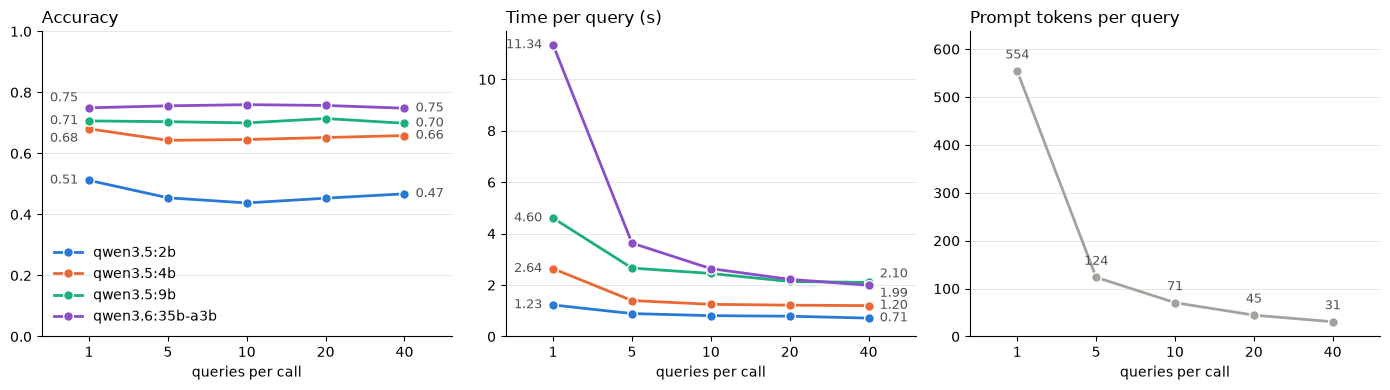

In [4]:
# vertical shifts (points) for value labels that would otherwise overlap
LABEL_SHIFT = {("accuracy", 1, "qwen3.6:35b-a3b"): 7, ("accuracy", 1, "qwen3.5:4b"): -7,
               ("time_per_query_s", 40, "qwen3.5:9b"): 6, ("time_per_query_s", 40, "qwen3.6:35b-a3b"): -6}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
x = {bs: i for i, bs in enumerate(BATCH_SIZES)}
for model in MODELS:
    m = mean.loc[model]
    for ax, col in [(axes[0], "accuracy"), (axes[1], "time_per_query_s")]:
        ax.plot([x[b] for b in m.index], m[col], color=COLORS[model], linewidth=2, marker="o", markersize=7,
                markeredgecolor="white", label=model)
        for b in (1, 40):
            ax.annotate(f"{m.loc[b, col]:.2f}", (x[b], m.loc[b, col]), textcoords="offset points",
                        xytext=(-8 if b == 1 else 8, LABEL_SHIFT.get((col, b, model), 0)),
                        ha="right" if b == 1 else "left", va="center",
                        fontsize=9, color="#52514e")
tokens = mean.loc[MODELS[0], "prompt_tokens_per_query"]
axes[2].plot([x[b] for b in tokens.index], tokens, color=GRAY, linewidth=2, marker="o", markersize=7,
             markeredgecolor="white")
for b, value in tokens.items():
    axes[2].annotate(f"{value:.0f}", (x[b], value), textcoords="offset points", xytext=(0, 9), ha="center",
                     fontsize=9, color="#52514e")
for ax, title in zip(axes, ["Accuracy", "Time per query (s)", "Prompt tokens per query"]):
    ax.set_xticks(range(len(BATCH_SIZES)), BATCH_SIZES)
    ax.set_xlim(-0.6, len(BATCH_SIZES) - 0.4)
    ax.set_xlabel("queries per call")
    ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[2].set_ylim(0, tokens.max() * 1.15)
axes[0].legend(frameon=False, loc="lower left")
plt.tight_layout()

## 3. Does the position in the batch matter?

Accuracy of the **first** query of each batch vs. all other queries (both seeds). The dashed line is one query
per call.

first query  n first  other queries  \
model           batch_size                                        
qwen3.5:2b      5                 0.318      154          0.489   
                10                0.269       78          0.457   
                20                0.150       40          0.470   
                40                0.100       20          0.477   
qwen3.5:4b      5                 0.610      154          0.651   
                10                0.667       78          0.643   
                20                0.675       40          0.651   
                40                0.600       20          0.660   
qwen3.5:9b      5                 0.656      154          0.716   
                10                0.718       78          0.698   
                20                0.775       40          0.711   
                40                0.650       20          0.700   
qwen3.6:35b-a3b 5                 0.714      154          0.766   
                10                0.744       78          0.762   
                20                0.700       40          0.760   
                40                0.650       20          0.751   

                            first query card_*  
model           batch_size                      
qwen3.5:2b      5                        0.273  
                10                       0.372  
                20                       0.525  
                40                       0.450  
qwen3.5:4b      5                        0.104  
                10                       0.141  
                20                       0.050  
                40                       0.050  
qwen3.5:9b      5                        0.110  
                10                       0.141  
                20                       0.075  
                40                       0.200  
qwen3.6:35b-a3b 5                        0.117  
                10                       0.128  
                20                       0.050  
                40                       0.100

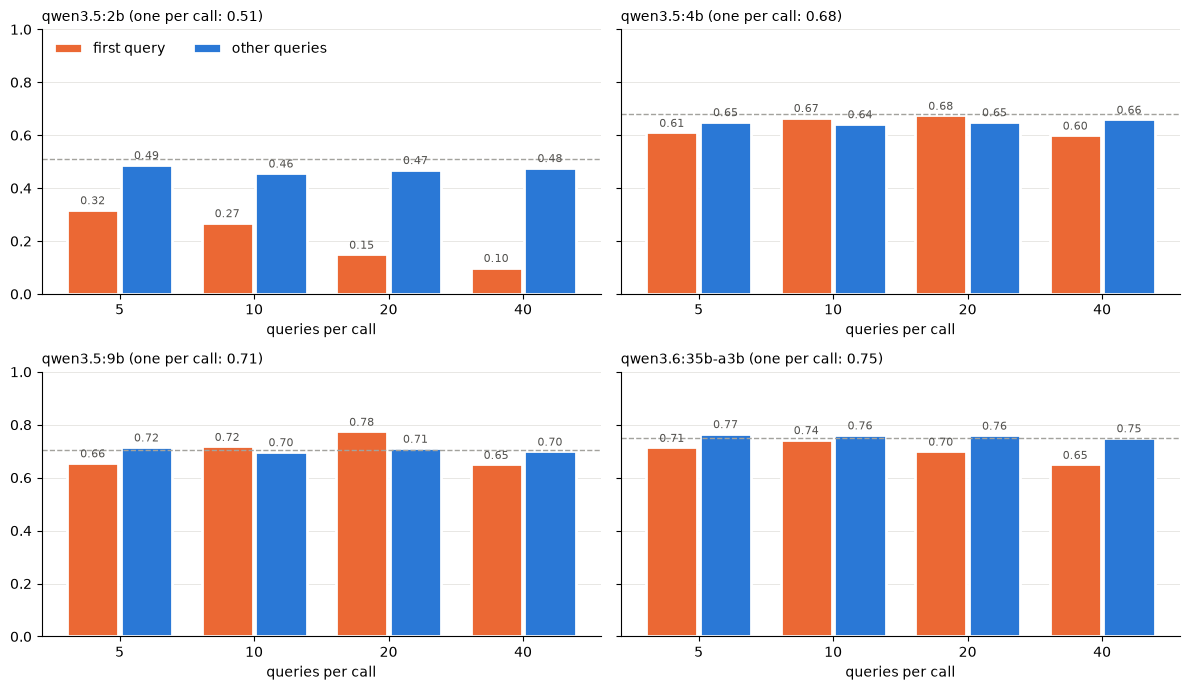

In [5]:
rows = []
for model in MODELS:
    for bs in BATCH_SIZES[1:]:
        r = pd.concat([results[model, bs, seed] for seed in SEEDS])
        first = r["position"] == 0
        rows.append({"model": model, "batch_size": bs, "first query": r.loc[first, "correct"].mean(),
                     "n first": first.sum(), "other queries": r.loc[~first, "correct"].mean(),
                     "first query card_*": r.loc[first, "prediction"].str.startswith("card_").mean()})
position = pd.DataFrame(rows).set_index(["model", "batch_size"])

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, model in zip(axes.flat, MODELS):
    p = position.loc[model]
    xs = np.arange(len(p))
    for offset, col, color in [(-0.2, "first query", "#eb6834"), (0.2, "other queries", "#2a78d6")]:
        bars = ax.bar(xs + offset, p[col], width=0.38, color=color, edgecolor="white", linewidth=2, label=col)
        for bar, value in zip(bars, p[col]):
            ax.annotate(f"{value:.2f}", (bar.get_x() + bar.get_width() / 2, value), textcoords="offset points",
                        xytext=(0, 4), ha="center", fontsize=8, color="#52514e")
    single = mean.loc[(model, 1), "accuracy"]
    ax.axhline(single, color=GRAY, linestyle="--", linewidth=1)
    ax.set_xticks(xs, p.index)
    ax.set_xlabel("queries per call")
    ax.set_title(f"{model} (one per call: {single:.2f})", loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
    ax.set_axisbelow(True)
axes[0, 0].set_ylim(0, 1)
axes[0, 0].legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout()
position.round(3)

The column `first query card_*` shows how often the first answer is a label starting with `card_`
(13% of the gold labels).

## 4. Do neighbouring queries influence each other?

The batches are random, so two neighbouring queries rarely share an intent. If the model's answers for
neighbours agree more often than their gold labels do, answers spill over from one query to the next.

In [6]:
rows = []
for (model, bs, seed), r in results.items():
    if bs == 1:
        continue
    r = r.sort_values(["batch", "position"])
    same_batch = r["batch"].eq(r["batch"].shift())
    rows.append({
        "model": model, "batch_size": bs,
        "neighbours with same gold label": (r["label"].eq(r["label"].shift()) & same_batch).sum() / same_batch.sum(),
        "neighbours with same prediction": (r["prediction"].eq(r["prediction"].shift()) & same_batch).sum() / same_batch.sum(),
        "distinct gold labels per batch": r.groupby("batch")["label"].nunique().mean(),
        "distinct predicted labels per batch": r.groupby("batch")["prediction"].nunique().mean(),
    })
pd.DataFrame(rows).groupby(["model", "batch_size"]).mean().round(3)

neighbours with same gold label  \
model           batch_size                                    
qwen3.5:2b      5                                     0.018   
                10                                    0.016   
                20                                    0.016   
                40                                    0.016   
qwen3.5:4b      5                                     0.018   
                10                                    0.016   
                20                                    0.016   
                40                                    0.016   
qwen3.5:9b      5                                     0.018   
                10                                    0.016   
                20                                    0.016   
                40                                    0.016   
qwen3.6:35b-a3b 5                                     0.018   
                10                                    0.016   
                20                                    0.016   
                40                                    0.016   

                            neighbours with same prediction  \
model           batch_size                                    
qwen3.5:2b      5                                     0.013   
                10                                    0.019   
                20                                    0.019   
                40                                    0.019   
qwen3.5:4b      5                                     0.010   
                10                                    0.010   
                20                                    0.015   
                40                                    0.015   
qwen3.5:9b      5                                     0.015   
                10                                    0.013   
                20                                    0.015   
                40                                    0.015   
qwen3.6:35b-a3b 5                                     0.015   
                10                                    0.013   
                20                                    0.014   
                40                                    0.017   

                            distinct gold labels per batch  \
model           batch_size                                   
qwen3.5:2b      5                                    4.890   
                10                                   9.385   
                20                                  17.400   
                40                                  31.350   
qwen3.5:4b      5                                    4.890   
                10                                   9.385   
                20                                  17.400   
                40                                  31.350   
qwen3.5:9b      5                                    4.890   
                10                                   9.385   
                20                                  17.400   
                40                                  31.350   
qwen3.6:35b-a3b 5                                    4.890   
                10                                   9.385   
                20                                  17.400   
                40                                  31.350   

                            distinct predicted labels per batch  
model           batch_size                                       
qwen3.5:2b      5                                         4.896  
                10                                        9.295  
                20                                       16.525  
                40                                       27.950  
qwen3.5:4b      5                                         4.922  
                10                                        9.385  
                20                                       17.025  
                40                             

## 5. Which answers change?

In [7]:
for model in MODELS:
    one, forty = results[model, 1, 0]["correct"], results[model, 40, 0]["correct"]
    print(model)
    print(pd.crosstab(one.rename("correct, 1 per call"), forty.rename("correct, 40 per call"), margins=True), "\n")

qwen3.5:2b
correct, 40 per call  False  True  All
correct, 1 per call                   
False                   155    33  188
True                     50   147  197
All                     205   180  385 

qwen3.5:4b
correct, 40 per call  False  True  All
correct, 1 per call                   
False                    96    27  123
True                     27   235  262
All                     123   262  385 

qwen3.5:9b
correct, 40 per call  False  True  All
correct, 1 per call                   
False                    94    21  115
True                     23   247  270
All                     117   268  385 

qwen3.6:35b-a3b
correct, 40 per call  False  True  All
correct, 1 per call                   
False                    75    18   93
True                     20   272  292
All                      95   290  385 



In [8]:
# The errors of the small model in one batch of 40: query, gold label and prediction
r = results[MODELS[0], 40, 0]
batch = r[r["batch"] == 0].sort_values("position")
batch.loc[~batch["correct"], ["position", "text", "label", "prediction"]].head(15)

,position,text,label,prediction
3000,0,What can I use to verify my identify?,verify_my_identity,verify_source_of_funds
285,3,Can you get me my card fast?,card_delivery_estimate,getting_virtual_card
1714,4,I would like to cancel a payment. I purchased ...,request_refund,card_payment_wrong_exchange_rate
2987,6,"I got my American Express in Apple Pay, why is...",apple_pay_or_google_pay,get_physical_card
2679,7,Can you tell me why my top up didn't work?,top_up_failed,card_not_working
1520,9,What do I do if I forget my passcode? Because...,passcode_forgotten,pin_blocked
2576,10,It seems I was overcharged when I used an ATM ...,wrong_exchange_rate_for_cash_withdrawal,exchange_charge
2110,12,"Hi, I would like to file a claim for an inquir...",reverted_card_payment?,Refund_not_showing_up
2766,18,How much more do I have to pay to exchange cur...,exchange_charge,exchange_rate
1030,19,Do you know if my top-up has been cancelled?,top_up_reverted,pending_card_payment


## Takeaways

* **Batching works for the larger models, not for the smallest one.** `9b` and `35b-a3b` keep their accuracy at
  every batch size (9b: 0.71 one per call, 0.70-0.71 batched; 35b-a3b: 0.75 and 0.75-0.76), `4b` loses 1-4 points,
  `2b` loses 4-7 points.
* **The cost drops a lot**: the prompt tokens per query fall from 554 to 31 (18x fewer), and the time per query
  roughly halves for `4b` and `9b` (2.6 s -> 1.2 s, 4.6 s -> 2.1 s). For `35b-a3b`, which runs partly on the CPU,
  it drops 5.7x (11.3 s -> 2.0 s): with batching, the largest model is as fast per query as `9b` and more accurate.
  Most of the gain comes already with 5 queries per call. With an API that bills per input token, the saving would
  be close to 18x.
* **The small model fails on the first query**: `2b` gets the first query of a batch right only 10-32% of the time
  (the larger the batch, the worse), vs. 46-49% for the other queries; it often answers with a `card_*` label.
  The larger models show at most a small dip (a few points, within the noise of 20-154 first queries).
* **No spill-over**: neighbouring queries get the same answer no more often than their gold labels agree, for all
  four models.
* **Same accuracy does not mean the same answers**: for `9b`, 21 answers are fixed and 23 broken between one and
  40 queries per call (35b-a3b: 18 and 20), i.e. about 10% of the answers change. The batch order matters too:
  the two random orders differ by up to 4 points (`4b`, 40 per call: 0.68 vs. 0.64), so differences of 1-2 points
  are noise. Even one query per call is not fully reproducible for `35b-a3b` (0.758 vs. 0.740 in two runs), because
  concurrent requests on the CPU are not bit-identical.